# Final Examination: TranslateAI Ancient Character Recognition

Total Marks: 100

**Instructions:**
1. Enter your course email in the cell below.
2. Read the story and problem descriptions carefully.
3. Complete the code in cells containing `# YOUR CODE HERE`. Do not modify the test cells.
4. Run all cells sequentially to ensure your tests pass before submitting.

In [ ]:
# Enter your course email here
student_email = "raihansarkerxjc82@gmail.com" # Example: "your.name@university.edu"

---

## 📖 TranslateAI — Digitizing History

You have just been hired as a Machine Learning Engineer at **TranslateAI**, a startup working with international museums. Your first task is to build a neural network that can automatically classify ancient Japanese cursive texts.

We will use the **KMNIST** dataset — 28x28 grayscale images of 10 cursive characters: *o, ki, su, tsu, na, ha, ma, ya, re, wo*.

To ensure top performance, you must optimize your deep learning pipeline using **Batch Normalization** and **Advanced Optimizers (Adam)**.

---

## Question 1: Load, Explore, & Preprocess Data (20 Marks)

### 1.1 Download the Dataset (5 Marks)

We will use `torchvision.datasets.KMNIST` to download the dataset.

Run the cell below to download the training and test sets:

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Class names for KMNIST
class_names = ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']

# Download KMNIST
full_train_dataset = torchvision.datasets.KMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.KMNIST(root='./data', train=False, download=True)

print(f"\nTraining set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")
print(f"Image shape: {full_train_dataset[0][0].size}")  # first img tar size dekhe nilam!


Training set size: 60000
Test set size: 10000
Image shape: (28, 28)


In [ ]:
# MyMods
# Reproducibility & Determinism:
"""The below setting is for PyTorch, NumPy, and Python's random states.
But did not set Sklearn's random state here, so we still have to set random_state=42 for sklearn/train_test_split.. etc & and writing explicitely inline is also recommended!

- if we leave random_state=none in tran_test_split etc, Scikit-learn will fall back to using the global NumPy random state. If the script runs linearly from top to bottom, it will produce a reproducible split because we seeded NumPy globally.
- Scikit-learn explicitly warns against relying on np.random.seed(). So its always still better to explicitly state the random
"""
import random
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    # torch.use_deterministic_algorithms(True)  # Forces PyTorch to only use deterministic algorithms --> regardless of training on CPU or GPU! else, slight different result might recived due to device switch!
    ## BUT Warning!!: Forcing full determinism across hardware can severely slow down the GPU training speed.
set_seed(42)

# Should always use GPU if available:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu') # cuda: NVDIA GPU, mps: Apple
print(f'Current Device: {device}')


Current Device: cpu


### 1.2 Visualize Sample Grayscale Images (5 Marks)

Create a **2x5 subplot figure** (figsize 12x5) showing one sample image from **each of the 10 classes**.
- Title each subplot with its class name
- Turn off axis ticks
- Ensure you use `cmap='gray'` for visualization.

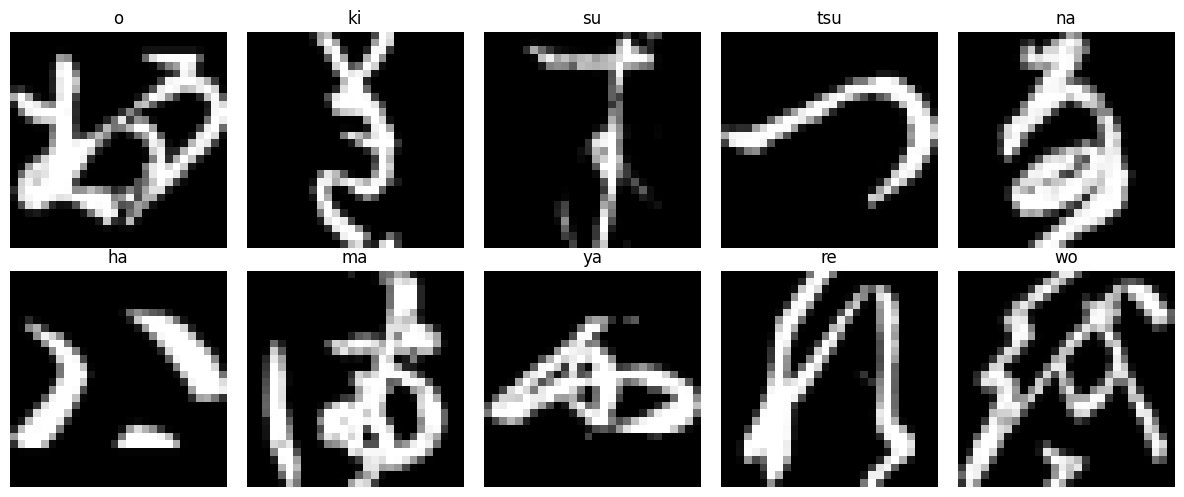

In [ ]:
"""Matplotlib MyNote: Matplotlib follows closest active canvas to draw on that, until it hits plt.show() then clears out.
plt.figure(figsize=(12, 5))  # <-- 1. Canvas A becomes "Active"
plt.subplot(2, 5, 1)          # <-- 2. Applies 2x5 grid tracking to Canvas A
# ... loop finishes ...
plt.show()                    # <-- 3. Canvas A is displayed and tracking closes
________________________________________________________________________________
MyNote (robust structure): general structure to draw almost anything:
# 1. Setup the canvas (fig) and the plotting slots (ax)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))

# 2. Draw your data directly onto the 'ax' object
ax.plot(x, y, label='Data Line')  # or ax.imshow(), ax.bar(), ax.scatter()

# 3. Customize the details (titles, labels, grid)
ax.set_title('Universal Plot Title')
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.legend()
ax.grid(True)

# 4. Clean up and display
plt.tight_layout()
plt.show()

# multi size hole ax.flatten() kore normally 'for loop' e iterate kora jabe!
"""
# Creating a 2x5 grid with a fixed figure size
fig, axes = plt.subplots(2, 5, figsize=(12, 5))   # axes are all the small grids in the big figure subplots()

# Flattening the axes array from 2D to 1D so we can loop over it easily (0 to 9)
axes = axes.flatten()
for i in range(len(np.unique(full_train_dataset.targets))):
    idx = np.where(full_train_dataset.targets == i)[0][0]       # jei target class er sathe match khabe shei class er first image ta niye ashbo.

    # Selecting the axis slot directly using standard 0-based indexing!
    axes[i].imshow(full_train_dataset.data[idx], cmap='gray')
    axes[i].set_title(class_names[i])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

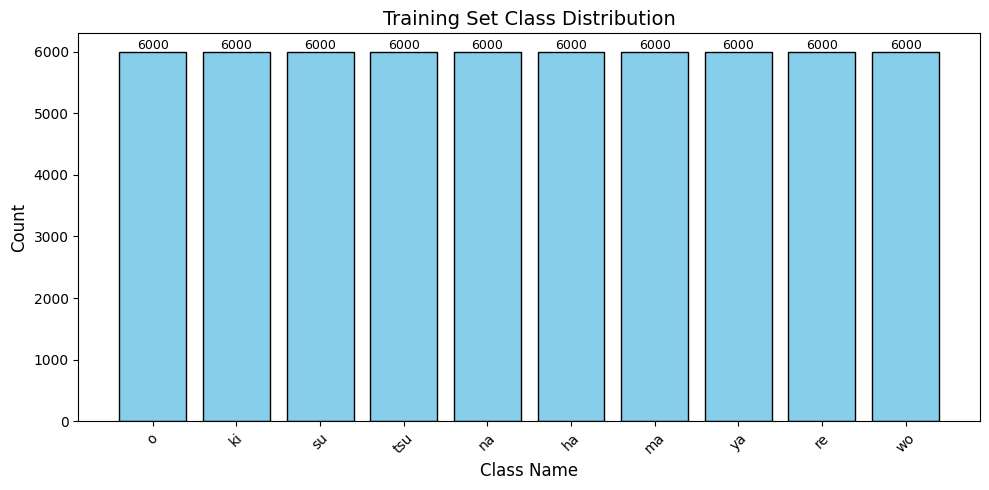

In [ ]:
# Extra: checking class distribution before applying multiclass loss and/or, softmax:
# Count occurrences of each class label
unique_labels, counts = np.unique(full_train_dataset.targets.numpy(), return_counts=True)

plt.figure(figsize=(10, 5))
bars = plt.bar(x=[class_names[i] for i in unique_labels], height=counts, color='skyblue', edgecolor='black')

plt.title("Training Set Class Distribution", fontsize=14)
plt.xlabel("Class Name", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.xticks(rotation=45)

# Adding counts on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0,  #center
        yval,
        f'{yval}',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

### 1.3 Data Scaling & Splitting (10 Marks)

**Your tasks:**
1. Extract images and labels from both train and test datasets as NumPy arrays. (Note: KMNIST images are 28x28)
2. Normalize the pixel values to the range [0, 1] by MinMax Scaling.
3. Split the training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
4. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (float32 tensors), `y_train, y_val, y_test` (long tensors)

In [ ]:
"""MyNote:
> Its best to do Normalization & Data split all using just PyTorch, instead of rigorously converting among numpy, sklearn, torch back-n-fourth.
-
we train on scaled data(X,y) so model expects same scale of input during inference of unseen or test data too. thus, we scale X_test too.
Later on, when an unseen input comes from real world, we manually handle the input by,
 convert to np.float32 -> scale by /255.0 -> torch.tensor -> push to model -> get prediction!

since because, PyTorch for DL has no ml like sklearn 'Pipeline' module all in one. so we do manual handling in dl.
"""
# Note: to use Sklearn's train_test_split, we require NumPy data, not tensors! so need to convert to NumPy first!

# NumPy convert + Min-Max scaling (ranges [0,1]) --> on Train and Test sets:
X_train_full_np = full_train_dataset.data.numpy().astype(np.float32) / 255.0   # images    -> shape: (60000, 28, 28)  # Numpy conversion + data scaling (MinMax)
y_train_full_np = full_train_dataset.targets.numpy().astype(np.float32)        # labels

X_test_np = test_dataset_raw.data.numpy().astype(np.float32) / 255.0           # images -> cnvrted to numpy for div calc. Though, tensor e rekheo kora jay. but scaling must kortei hobe.
y_test_np = test_dataset_raw.targets.numpy()                                   # labels

# ML er Sklearn's library Numpy/pd niye kaj korte pare and also returns as NumPY like data splits
# Returned X_train, y_train, X_val, y_val are NumPy here..
X_train_np, X_val_np, y_train_np, y_val_np = train_test_split(X_train_full_np, y_train_full_np, test_size=10000, random_state=42) # stratify=y not needed, already balanced



# PyTorch Tensor for ANN --> from NumPy:                                    # make tensor varibales --> X_train, y_train, X_val, y_val, X_test, y_test
X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)

X_val = torch.tensor(X_val_np, dtype=torch.float32)
y_val =  torch.tensor(y_val_np, dtype=torch.long)

X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.long)

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28)
assert X_train.dtype == torch.float32
assert y_train.dtype == torch.long
print("✅ Q1.3 Passed!")

✅ Q1.3 Passed!


---

## Question 2: Build PyTorch DataLoaders (15 Marks)

Create `TensorDataset` and `DataLoader` objects for train, validation, and test sets.

- **batch_size = 256**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

<font color="red">**HAS GPU CONFIG !**</font>

In [ ]:
# DataSet
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# DataLoaders:  [pin_memory=True for GPU]
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True,    pin_memory=True)    # pin_memory=True For GPU !
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False,       pin_memory=True)    # shuffle false for testing datas (kept untouched)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False,     pin_memory=True)    # shuffle false for testing datas (kept untouched)

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (256, 28, 28)
assert batch_y.dtype == torch.long
print("✅ Q2 Passed!")

✅ Q2 Passed!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


---

## Question 3: Deep Neural Network Architecture (25 Marks)

Create a class `TranslateAIClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture. Since the input is `28x28`, the flattened size is **784**.

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28x28 → 784 |
| Linear | 784 → 512 |
| BatchNorm1d | Batch Normalization (512 features) |
| ReLU | Activation |
| Linear | 512 → 256 |
| BatchNorm1d | Batch Normalization (256 features) |
| ReLU | Activation |
| Linear | 256 → 128 |
| BatchNorm1d | Batch Normalization (128 features) |
| ReLU | Activation |
| Linear | 128 → 10 |

After defining the class, create an instance called `model` and print it.

<font color="red">**HAS GPU CONFIG !**</font>

In [ ]:
class TranslateAIClassifier(nn.Module):
  def __init__(self, input_dim=28*28, num_classes=10):
    super().__init__()
    self.network = nn.Sequential(
        # Flattening for ANN:
        nn.Flatten(),

        # Layer1: Input-Layer
        nn.Linear(input_dim, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),

        # Layer2:
        nn.Linear(512, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),

        # Layer3:
        nn.Linear(256, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),

        # Layer4: Final-Layer
        nn.Linear(128, num_classes)   # 10 MultiClasses
    )

  def forward(self, x):
    return self.network(x)            # y_pred  :uses the above architecture and yelds y_pred (Forward Pass)

# Model instance and Printing architecture:
model = TranslateAIClassifier()
model = model.to(device)          # For GPU !
print(model)

TranslateAIClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10)
has_batchnorm = any(isinstance(m, nn.BatchNorm1d) for m in model.modules())
assert has_batchnorm, "Model must include BatchNorm1d layers"
print("✅ Q3 Passed!")

✅ Q3 Passed!


---

## Question 4: Advanced Training Pipeline (25 Marks)

### 4.1 Setup Optimizer and Loss (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.Adam` with `lr=0.001`
- Number of epochs: **15**

In [ ]:
loss_func = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 15

### 4.2 PyTorch Training Pipeline (20 Marks)

Write the training loop for **15 epochs**.

For each epoch:
1. Set model to training mode (`model.train()`)
2. Train on `train_loader` (forward pass, calculate loss, backward pass, optimizer step)
3. Set model to evaluation mode (`model.eval()`)
4. Evaluate on `val_loader` and compute validation loss and accuracy.
5. Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f}`

Store: `train_losses`, `val_losses` lists.

<font color="red">**HAS GPU CONFIG !**</font>

In [ ]:
# Time Tracker:
# Start Time:
import time
if torch.cuda.is_available():
    torch.cuda.synchronize()  # Synchronize (with GPU) before starting the clock
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    torch.mps.synchronize()
start_time = time.time()
# -------------------------------------------------------------------------------------------------------------

# ----- THE TRAINING LOOP: -----
# Empty List for record of each epochs!
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    # --- TRAINING ---
    model.train()   # Training Mode Switch
    train_correct = 0
    train_total = 0

    train_loss = 0.0
    for images_Xbatch, labels_ybatch in train_loader:
      # handing over to Active device (if available, GPU!):
      images_Xbatch = images_Xbatch.to(device)
      labels_ybatch = labels_ybatch.to(device)

      # - Main:-
      optimizer.zero_grad()
      outputs_ybatch = model(images_Xbatch)  # prediction for the full batch
      loss_ofBatch = loss_func(outputs_ybatch, labels_ybatch)
      loss_ofBatch.backward()
      optimizer.step()

      # - batch report -
      """Note:
      how does outputs_ybatch look like?
      ==>
      outputs_ybatch = tensor([
          [-2.34,  5.12, -0.89, ...,  1.20],  # Row for Image 1 (List of Scores, for all 10 classes)
          [ 0.45, -1.10,  3.89, ..., -0.54],  # Row for Image 2
          ...                                  # (256 rows total)
      ])
      """
      preds_ybatch = torch.argmax(outputs_ybatch, dim=1)    # Row borabor max er index no.
      train_correct += (preds_ybatch == labels_ybatch).sum().item()
      train_total += labels_ybatch.size(0)  # .size() diyei size jana jay but outputs like torch.tensor([the_size]) so first item is idx=0

      train_loss += loss_ofBatch.item() * images_Xbatch.size(0)

    # - epoch training reports -
    epoch_train_loss = train_loss / train_total             # len(train_loader.dataset) diyeo ber kora jay, if tracking not needed on each batch
    epoch_train_acc = (train_correct / train_total) * 100.0
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- VALIDATION ---
    model.eval()   # Evaluation Mode Switch
    val_correct = 0
    val_total = 0

    val_loss = 0.0
    with torch.no_grad():   # Gradient tracking not needed at all during inference
      for images_Xbatch, labels_ybatch in val_loader:
        # handing over to Active device (if available, GPU!):
        images_Xbatch = images_Xbatch.to(device)
        labels_ybatch = labels_ybatch.to(device)

        # - Main:-
        # optimizer.zero_grad()
        outputs_ybatch = model(images_Xbatch)
        loss = loss_func(outputs_ybatch, labels_ybatch)
        # loss.backward()
        # optimizer.step()

        # - batch report -
        preds_ybatch = torch.argmax(outputs_ybatch, dim=1)    # Row borabor max er index no.
        val_correct += (preds_ybatch == labels_ybatch).sum().item()
        val_total += labels_ybatch.size(0)  # .size() diyei size jana jay but outputs like torch.tensor([the_size]) so first item is idx=0
        val_loss += loss.item() * images_Xbatch.size(0)

    # - epoch val reports -
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100.0
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f'Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}')



# -------------------------------------------------------------------------------------------------------------
# Synchronizing time again before stopping the clock:
if torch.cuda.is_available():
    torch.cuda.synchronize()
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    torch.mps.synchronize()

end_time = time.time()
elapsed_time = end_time - start_time
minutes = int(elapsed_time // 60)
seconds = elapsed_time % 60
print("\nElapsed Time: {} minutes and {:.2f} seconds".format(minutes, seconds))

Epoch 1/15 | Train Loss: 0.3835 | Val Loss: 0.1969
Epoch 2/15 | Train Loss: 0.1340 | Val Loss: 0.1606
Epoch 3/15 | Train Loss: 0.0804 | Val Loss: 0.1310
Epoch 4/15 | Train Loss: 0.0494 | Val Loss: 0.1459
Epoch 5/15 | Train Loss: 0.0389 | Val Loss: 0.1467
Epoch 6/15 | Train Loss: 0.0262 | Val Loss: 0.1408
Epoch 7/15 | Train Loss: 0.0228 | Val Loss: 0.1587
Epoch 8/15 | Train Loss: 0.0204 | Val Loss: 0.1485
Epoch 9/15 | Train Loss: 0.0135 | Val Loss: 0.1456
Epoch 10/15 | Train Loss: 0.0153 | Val Loss: 0.1456
Epoch 11/15 | Train Loss: 0.0163 | Val Loss: 0.1569
Epoch 12/15 | Train Loss: 0.0162 | Val Loss: 0.1525
Epoch 13/15 | Train Loss: 0.0091 | Val Loss: 0.1502
Epoch 14/15 | Train Loss: 0.0102 | Val Loss: 0.1764
Epoch 15/15 | Train Loss: 0.0088 | Val Loss: 0.1678

Elapsed Time: 0 minutes and 58.72 seconds


In [ ]:
# # Accuracies:
# print(f'Train Accuracies: \n{np.array(train_accuracies)}')
# print(f'Validation Accuracies: \n{np.array(val_accuracies)}')

# # Losses:
# print(f'\nTraining Losses: \n{np.array(train_losses)}')
# print(f'Validation Losses: \n{np.array(val_losses)}')

# Final Accuracies of each set (the last item in the arrays)
print(f"\nFinal Training Accuracy (at last epoch):   {train_accuracies[-1]:.2f}%")
print(f"Final Validation Accuracy (at last epoch): {val_accuracies[-1]:.2f}%")


Final Training Accuracy (at last epoch):   99.72%
Final Validation Accuracy (at last epoch): 96.24%


- The model is Overfitting!

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
print("✅ Q4.2 Passed!")

✅ Q4.2 Passed!


---

## Question 5: Evaluation & Analytics (15 Marks)

### 5.1 Test Evaluation (5 Marks)
Evaluate the model on the **test set**.
- Print the Test Accuracy.
- Collect Test dataset's all predictions into a list called `all_preds`.

In [ ]:
model.eval()
all_preds, all_labels = [], []

test_correct = 0
test_total = 0

with torch.no_grad():
  for images_xbatch, labels_ybatch in test_loader:
    # handing over to Active device (if available, GPU!):
    images_xbatch = images_xbatch.to(device)
    labels_ybatch = labels_ybatch.to(device)

    # - Main:-
    outputs_ybatch = model(images_xbatch)
    preds_ybatch = torch.argmax(outputs_ybatch, dim=1)  # _, preds_ybatch = torch.max(outputs.data, 1)  # provides val, index

    test_correct += (preds_ybatch == labels_ybatch).sum().item()
    test_total += labels_ybatch.size(0)
    all_preds.extend(preds_ybatch.cpu().numpy())  # uses CPU before NumPy needs it
    all_labels.extend(labels_ybatch.cpu().numpy())  # uses CPU before NumPy needs it

test_accuracy = (test_correct/test_total) * 100.0
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 91.74%


### 5.2 Plot Learning Curves (5 Marks)
Plot **Training Loss** and **Validation Loss** on the same figure across epochs. Include a legend and title.

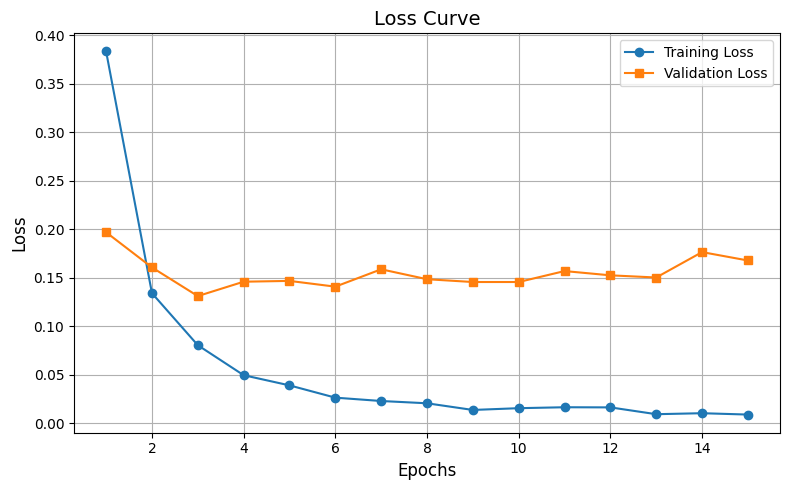

In [ ]:
# Setup the canvas and the single plotting area (1x1 grid)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))

# Drawing data lines onto the 'ax' object
ax.plot(range(1, epochs + 1), train_losses, label='Training Loss', marker='o')
ax.plot(range(1, epochs + 1), val_losses, label='Validation Loss', marker='s')

# Customizing the details using the '.set_' methods
ax.set_title("Loss Curve", fontsize=14)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.legend()
ax.grid(True)

# Cleaning up and display
plt.tight_layout()
plt.show()


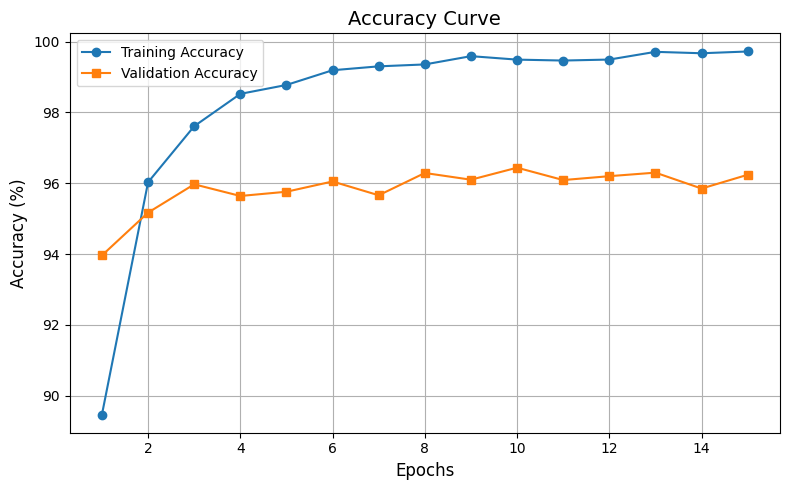

In [ ]:
# Extra: Training Vs Validation Accuracy Graph:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))

ax.plot(range(1, epochs+1), train_accuracies, label='Training Accuracy', marker='o')
ax.plot(range(1, epochs+1), val_accuracies, label='Validation Accuracy', marker='s')

ax.set_title("Accuracy Curve", fontsize=14)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

- The model is Overfitting!

### 5.3 Confusion Matrix & Analysis (5 Marks)
1. Plot the confusion matrix using `ConfusionMatrixDisplay`.
2. Write a brief markdown explanation of which ancient character classes are most frequently confused by the model based on the matrix.

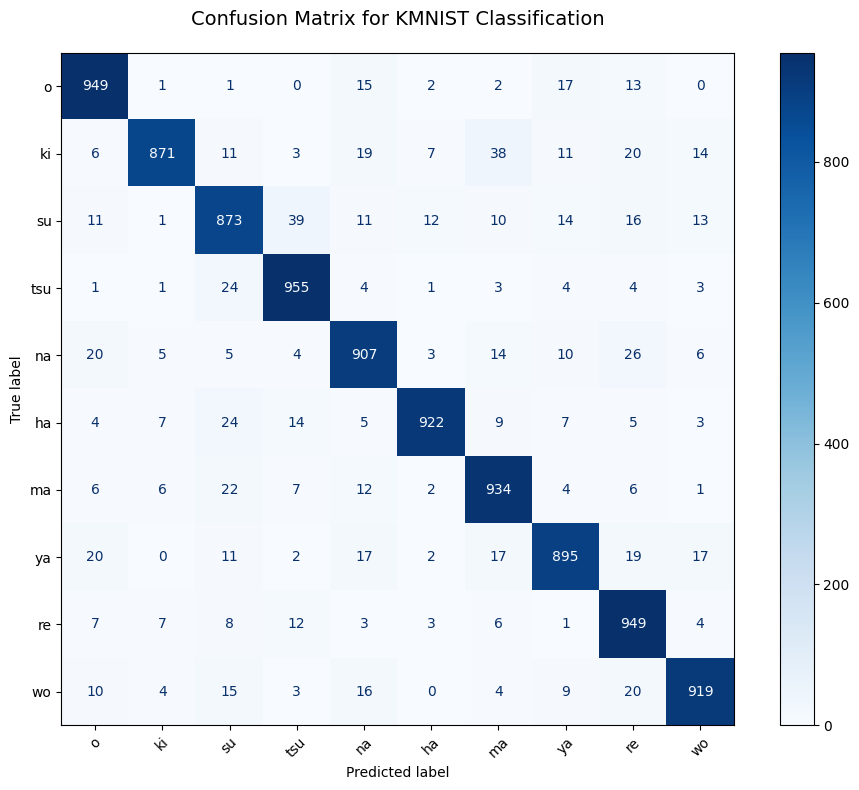

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

my_cm = confusion_matrix(y_test, all_preds)
disp = ConfusionMatrixDisplay(
    confusion_matrix=my_cm,
    display_labels=class_names
)

# Setting up the canvas for plotting:
fig, ax = plt.subplots(figsize=(10, 8))

# Passing the 'ax' directly to the scikit-learn display tool
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45) # 'vertical'

# Customizing using the 'ax' object directly
ax.set_title("Confusion Matrix for KMNIST Classification", fontsize=14, pad=20)

# Cleaning up and display
plt.tight_layout()
plt.show()

In [ ]:
top_n = 10                       # How many 'Highest_misclassifications' I want to see!
cm_errors = my_cm.copy()        # Copying cm
np.fill_diagonal(cm_errors, 0)  # zero-out the diagonal (ignoring correct predictions)

# Getting indices of the top N highest errors, sorted descending
flat_indices = np.argsort(cm_errors.ravel())[::-1][:top_n]
top_errors = np.unravel_index(flat_indices, cm_errors.shape)

# Printing the top misclassifications:
print(f"--- Top {top_n} Most Misclassified Pairs ---")
for i in range(top_n):
    true_idx = top_errors[0][i]
    pred_idx = top_errors[1][i]
    count = cm_errors[true_idx, pred_idx]

    # Map index numbers to actual class names
    true_name = class_names[true_idx]
    pred_name = class_names[pred_idx]

    print(f"{i+1}. True: '{true_name}' misclassified as Pred: '{pred_name}' -> {count} times")


--- Top 10 Most Misclassified Pairs ---
1. True: 'su' misclassified as Pred: 'tsu' -> 39 times
2. True: 'ki' misclassified as Pred: 'ma' -> 38 times
3. True: 'na' misclassified as Pred: 're' -> 26 times
4. True: 'ha' misclassified as Pred: 'su' -> 24 times
5. True: 'tsu' misclassified as Pred: 'su' -> 24 times
6. True: 'ma' misclassified as Pred: 'su' -> 22 times
7. True: 'ki' misclassified as Pred: 're' -> 20 times
8. True: 'na' misclassified as Pred: 'o' -> 20 times
9. True: 'wo' misclassified as Pred: 're' -> 20 times
10. True: 'ya' misclassified as Pred: 'o' -> 20 times


*Double-click here to write your analysis*

**Your Analysis:**
___
- Based on the confusion matrix, the model occasionally confuses `su` with `tsu` (counted $39$ from the matrix) and `ki` with `ma` (counted $38$ from the matrix) as they look similar to each other.



+ and, since the model is **Overfitting**:
We may try below techniques to reduce the overfitting issues:
  - Adding `Dropout` layers inside the network (_for example: `nn.Dropout(0.3)` after activations_).
  - Adding `Weight Decay` (_**L2** regularization_) into the optimizer:
  > `optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)`
  - Apply `Early-Stoping` if middle epoch has lower loss compared to last Final epoch.